In [1]:
# sklearn for modeling, shap for interpretability, joblib to save artifacts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import (
    train_test_split, 
    cross_val_score, 
    StratifiedKFold,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve, 
    average_precision_score,
    f1_score, 
    recall_score, 
    precision_score
)

from sklearn.calibration import CalibrationDisplay
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import joblib

In [2]:
DATA_DIR = Path('..') / 'data'

df = pd.read_csv(DATA_DIR / 'processed' / 'churn_clean.csv')

In [3]:
df = df.drop('customerID', axis=1)

In [4]:
# Convert target to binary so sklearn metrics work correctly (No=0, Yes=1)

df['Churn'] = df['Churn'].map({'No':0, 'Yes':1})

In [5]:
df.select_dtypes(include=['object', 'string']).columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'tenure_group'],
      dtype='str')

In [6]:
x = df.drop('Churn', axis=1)
y = df['Churn']

In [7]:
# stratify=y keeps the churn ratio (~26%) consistent across both splits

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
# CLV feature engineering. Fitted on training data only to prevent leakage
def add_clv(df_subset, medians):
    df_subset = df_subset.copy()
    df_subset['expected_lifespan'] = df_subset['Contract'].map(medians)
    # Blends contract expectation with a 30% tenure factor, clipped to 6–72 months
    df_subset['remaining_lifetime'] = (
        (df_subset['expected_lifespan'] - df_subset['tenure']).clip(lower=0)
        + df_subset['tenure'] * 0.3
    ).clip(lower=6, upper=72)
    df_subset['CLV'] = df_subset['MonthlyCharges'] * df_subset['remaining_lifetime']
    return df_subset.drop(['expected_lifespan', 'remaining_lifetime'], axis=1)

# Medians from train only. Same values applied to test to avoid leakage
contract_medians = {
    'Month-to-month': x_train[x_train['Contract'] == 'Month-to-month']['tenure'].median(),
    'One year':       x_train[x_train['Contract'] == 'One year']['tenure'].median(),
    'Two year':       x_train[x_train['Contract'] == 'Two year']['tenure'].median()
}

x_train = add_clv(x_train, contract_medians)
x_test  = add_clv(x_test,  contract_medians)

print("CLV added. Shapes:", x_train.shape, x_test.shape)

CLV added. Shapes: (5625, 21) (1407, 21)


In [9]:
num = ['tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']
cat = x_train.select_dtypes(include=['object', 'string']).columns.tolist()

def make_pipe(**lr_params):
    """Scaling + encoding + LR in one object, so the app uses the exact same steps."""
    prep = ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat),
    ], remainder='passthrough', verbose_feature_names_out=False)
    return Pipeline([('prep', prep),
                    ('model', LogisticRegression(max_iter=1000, **lr_params))])

# Building First Model

## Logistic Regression

In [10]:
# Baseline, just to see where we start
model = make_pipe()
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['gender','SeniorCitizen','Partner',...,'TotalCharges','tenure_group', 'CLV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [11]:
# Grid search over C with class_weight='balanced' to handle the churn minority class

param_grid = {'model__C': [0.01, 0.1, 1, 10, 100]} # 'model__' = step name in the pipeline
grid = GridSearchCV(
   make_pipe(class_weight='balanced'),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)
grid.fit(x_train, y_train)

print(f"Best C: {grid.best_params_['model__C']}")
print(f"Best CV AUC: {grid.best_score_:.4f}")

model_balanced = grid.best_estimator_
pipe = model_balanced      # name used later in the business layer and save cell

Best C: 100
Best CV AUC: 0.8466


In [12]:
# Unbalanced model baseline, expected to miss a lot of churners

y_pred = model.predict(x_test)

In [13]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[920 113]
 [178 196]]
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



### ROC-AUC

In [14]:
y_prob = model.predict_proba(x_test)[:,1]
roc_auc_score(y_test, y_prob)

0.8354812575386573

### Threshold Tuning (0.3 Example)

In [15]:
y_pred_03 = (y_prob > 0.3).astype(int)

In [16]:
print(confusion_matrix(y_test, y_pred_03))
print(classification_report(y_test, y_pred_03))

[[763 270]
 [ 89 285]]
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1033
           1       0.51      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.76      1407



### Fix Class Imbalance

#### Balanced Logistic Regression

=== Model Comparison ===
                         Model  ROC-AUC  Recall  Precision     F1
           Logistic Regression   0.8355  0.5241     0.6343 0.5739
Logistic Regression (balanced)   0.8338  0.7995     0.4910 0.6083


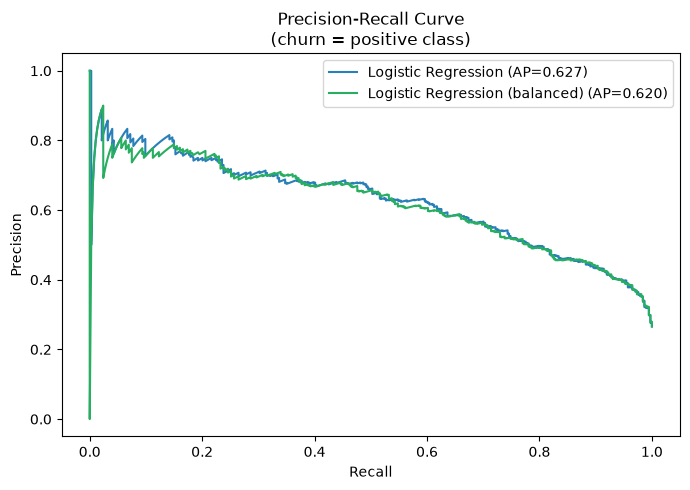


Selected model: Logistic Regression (balanced)
Reason: higher recall, better suited for imbalanced churn detection.


In [17]:
# Probabilities from both models
y_prob_lr      = model.predict_proba(x_test)[:, 1]
y_prob_lr_bal  = model_balanced.predict_proba(x_test)[:, 1]

# Predictions at default 0.5 threshold
y_pred_lr      = model.predict(x_test)
y_pred_lr_bal  = model_balanced.predict(x_test)

# Comparison table
comparison = pd.DataFrame({
    'Model':     ['Logistic Regression', 'Logistic Regression (balanced)'],
    'ROC-AUC':   [roc_auc_score(y_test, y_prob_lr),
                  roc_auc_score(y_test, y_prob_lr_bal)],
    'Recall':    [recall_score(y_test, y_pred_lr),
                  recall_score(y_test, y_pred_lr_bal)],
    'Precision': [precision_score(y_test, y_pred_lr),
                  precision_score(y_test, y_pred_lr_bal)],
    'F1':        [f1_score(y_test, y_pred_lr),
                  f1_score(y_test, y_pred_lr_bal)]
}).round(4)

print("=== Model Comparison ===")
print(comparison.to_string(index=False))

# Precision-Recall curves
fig, ax = plt.subplots(figsize=(7, 5))
for y_prob, label, color in [
    (y_prob_lr,     'Logistic Regression',            '#2980b9'),
    (y_prob_lr_bal, 'Logistic Regression (balanced)', '#27ae60')
]:
    p, r, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax.plot(r, p, label=f'{label} (AP={ap:.3f})', color=color)

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve\n(churn = positive class)')
ax.legend()
plt.tight_layout()
plt.show()

print("\nSelected model: Logistic Regression (balanced)")
print("Reason: higher recall, better suited for imbalanced churn detection.")

## SHAP Values

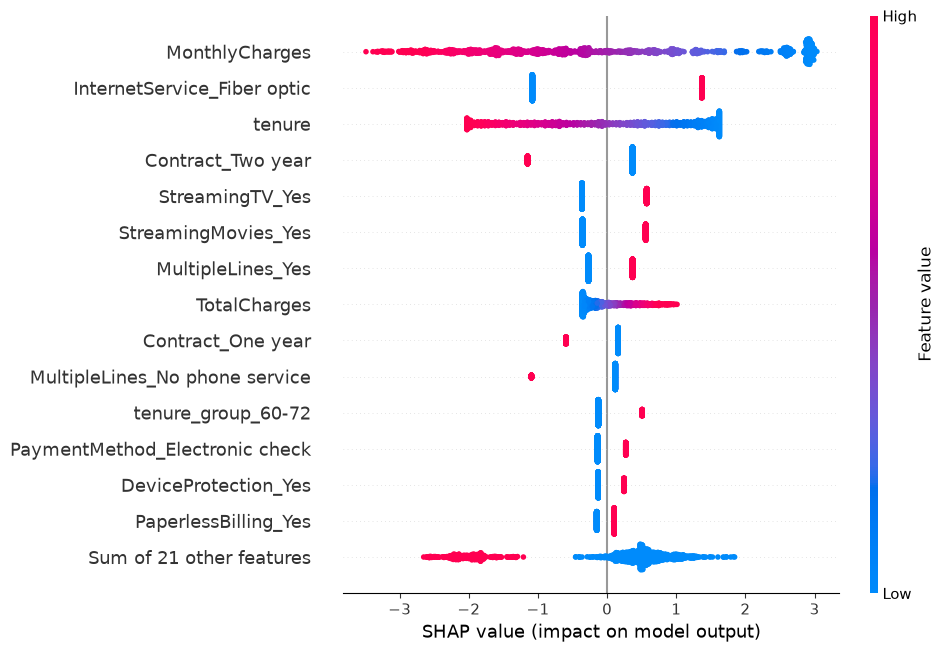

In [18]:
# LinearExplainer is exact for linear models. Each value shows how much
# a feature pushed the prediction away from the baseline.

X_train_t = pipe['prep'].transform(x_train)
X_test_t  = pipe['prep'].transform(x_test)
feature_names = pipe['prep'].get_feature_names_out()

explainer = shap.LinearExplainer(pipe['model'], shap.maskers.Independent(
    X_train_t, max_samples=len(X_train_t)))
shap_values = explainer.shap_values(X_test_t)

shap_explanation = shap.Explanation(
    values=shap_values, base_values=explainer.expected_value,
    data=X_test_t, feature_names=list(feature_names)
)
shap.plots.beeswarm(shap_explanation, max_display=15, show=True)

ROC-AUC  raw 0.8338 | calibrated 0.8341
Brier    raw 0.1738 | calibrated 0.1408
Mean p   raw 0.420 | calibrated 0.272 | actual churn 0.266


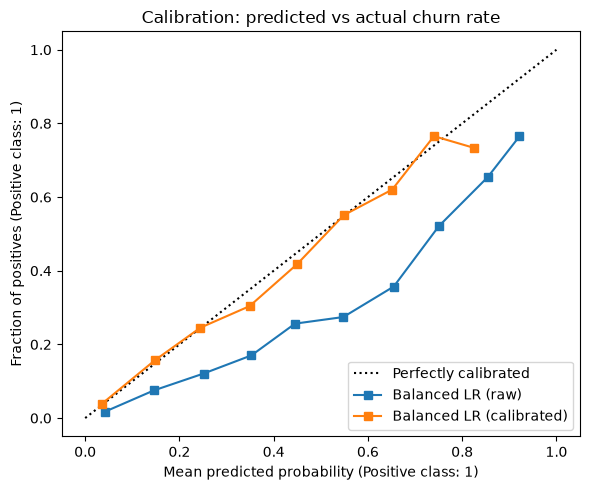

In [19]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

# class_weight='balanced' pushes probabilities up. Sigmoid calibration fixes this
# without changing the ranking (AUC stays the same).
cal_pipe = CalibratedClassifierCV(clone(pipe), method='sigmoid', cv=5)
cal_pipe.fit(x_train, y_train)
y_prob_cal = cal_pipe.predict_proba(x_test)[:, 1]

print(f"ROC-AUC  raw {roc_auc_score(y_test, y_prob_lr_bal):.4f} | calibrated {roc_auc_score(y_test, y_prob_cal):.4f}")
print(f"Brier    raw {brier_score_loss(y_test, y_prob_lr_bal):.4f} | calibrated {brier_score_loss(y_test, y_prob_cal):.4f}")
print(f"Mean p   raw {y_prob_lr_bal.mean():.3f} | calibrated {y_prob_cal.mean():.3f} | actual churn {y_test.mean():.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, y_prob_lr_bal, n_bins=10, ax=ax, name='Balanced LR (raw)')
CalibrationDisplay.from_predictions(y_test, y_prob_cal,    n_bins=10, ax=ax, name='Balanced LR (calibrated)')
ax.set_title('Calibration: predicted vs actual churn rate')
plt.tight_layout()
plt.show()

The balanced model over-predicts churn at every level (mean predicted 0.42 vs actual 0.27). Sigmoid calibration (5-fold) brings the mean to the actual rate and lowers the Brier score from 0.17 to 0.14, while AUC is unchanged, because calibration rescales probabilities without changing the ranking. Calibrated probabilities are used for everything that involves money: expected loss, profit-based threshold and priority score.

=== Top 10 features by churn impact ===
                       feature  coefficient
   InternetService_Fiber optic     2.451757
                MonthlyCharges    -1.953343
             Contract_Two year    -1.516614
                        tenure    -1.261474
MultipleLines_No phone service    -1.212792
               StreamingTV_Yes     0.936035
           StreamingMovies_Yes     0.914176
             Contract_One year    -0.754067
             MultipleLines_Yes     0.637299
            tenure_group_60-72     0.633001


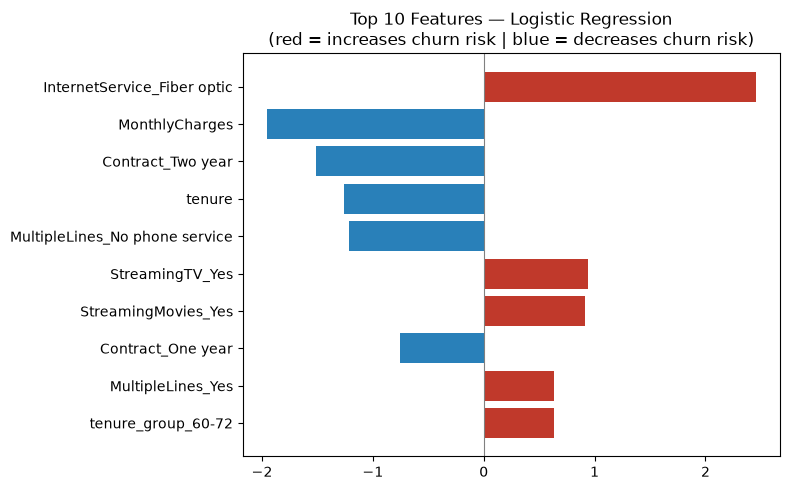

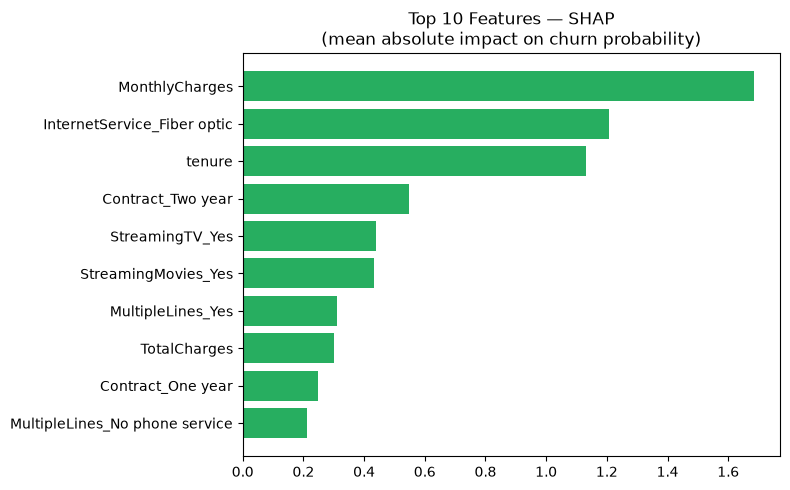


=== Where both methods agree (top 5) ===
{'MonthlyCharges', 'tenure', 'InternetService_Fiber optic', 'Contract_Two year'}


In [20]:
# Coefficients are comparable because features were StandardScaled
lr_importance = pd.DataFrame({
    'feature':     feature_names,
    'coefficient': pipe['model'].coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print("=== Top 10 features by churn impact ===")
print(lr_importance.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
top10 = lr_importance.head(10)
colors = ['#c0392b' if v > 0 else '#2980b9' for v in top10['coefficient']]
ax.barh(top10['feature'], top10['coefficient'], color=colors)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_title('Top 10 Features — Logistic Regression\n(red = increases churn risk | blue = decreases churn risk)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# SHAP: mean absolute value per feature
shap_mean = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=feature_names
).sort_values(ascending=True).tail(10)

fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.barh(shap_mean.index, shap_mean.values, color='#27ae60')
ax2.set_title('Top 10 Features — SHAP\n(mean absolute impact on churn probability)')
plt.tight_layout()
plt.show()

# Features both methods agree on are the most trustworthy signals
print("\n=== Where both methods agree (top 5) ===")
lr_top = set(lr_importance.head(5)['feature'])
shap_top = set(shap_mean.tail(5).index)
agreed = lr_top & shap_top
print(agreed if agreed else "Check top 10 for overlaps")

# Threshold Tuning

 threshold  contacted  churners_caught   recall  net_profit
      0.05       1033              367 0.981283       38154
      0.10        889              354 0.946524       38574
      0.15        805              343 0.917112       38318
      0.20        724              328 0.877005       36818
      0.25        629              305 0.815508       37151
      0.30        561              288 0.770053       37133
      0.35        499              270 0.721925       35118
      0.40        436              250 0.668449       32630
      0.45        365              223 0.596257       29690
      0.50        302              194 0.518717       26658
      0.55        257              174 0.465241       24950
      0.60        204              140 0.374332       20628
      0.65        154              107 0.286096       16212
      0.70         96               73 0.195187       11936
      0.75         43               33 0.088235        5715
      0.80         15               11 0

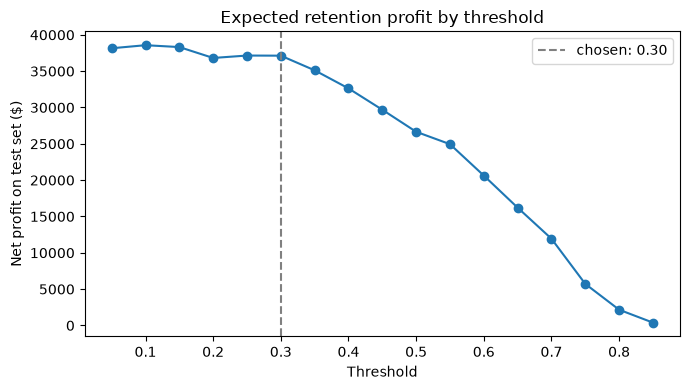

In [21]:
# Choose the threshold by expected profit, on calibrated probabilities.
# Assumptions (business inputs, adjust if needed):
OFFER_COST = 50     # $ cost of one retention offer (discount / call)
SAVE_RATE  = 0.30   # share of contacted churners who stay because of the offer

y_prob = y_prob_cal
clv_test = x_test['CLV'].values
churned  = y_test.values == 1

rows = []
for t in np.arange(0.05, 0.90, 0.05):
    flagged = y_prob >= t
    saved_revenue = SAVE_RATE * clv_test[flagged & churned].sum()
    cost = OFFER_COST * flagged.sum()
    rows.append({'threshold': round(t, 2),
                 'contacted': flagged.sum(),
                 'churners_caught': (flagged & churned).sum(),
                 'recall': (flagged & churned).sum() / churned.sum(),
                 'net_profit': round(saved_revenue - cost)})

profit_table = pd.DataFrame(rows)
print(profit_table.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(profit_table['threshold'], profit_table['net_profit'], marker='o')
plt.axvline(0.30, color='gray', linestyle='--', label='chosen: 0.30')
plt.xlabel('Threshold'); plt.ylabel('Net profit on test set ($)')
plt.title('Expected retention profit by threshold')
plt.legend(); plt.tight_layout(); plt.show()

Profit is almost flat between 0.05 and 0.30 (≈ $37–38K on the test set) and falls after 0.30. 0.30 is chosen: it keeps nearly the maximum profit while contacting about 46% fewer customers than 0.05, which matters because a retention team has limited capacity. The $50 offer cost and 30% save rate are assumptions; the app's slider lets the business change the threshold.

### ROC Curve Visualization

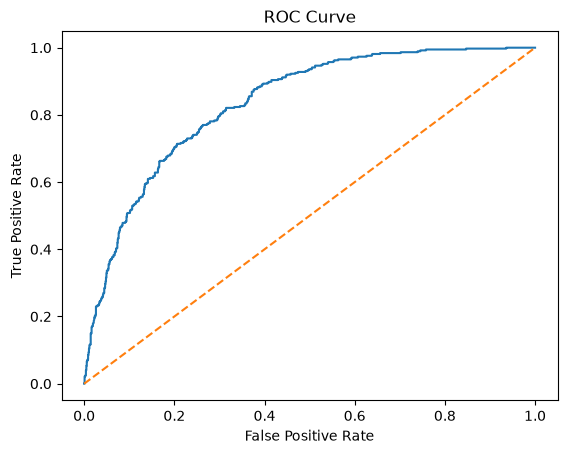

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

## CLV + Business Layer

In [23]:
# Score the full dataset with the calibrated pipeline (scaling + encoding happen inside)
df_full = add_clv(df.drop('Churn', axis=1), contract_medians)

df['CLV'] = df_full['CLV']
df['churn_probability'] = cal_pipe.predict_proba(df_full)[:, 1]

### Risk Segmentation

In [24]:
# Same rule as app.py: <0.30 Low, 0.30–0.60 Medium, >=0.60 High
df['risk_segment'] = pd.cut(
    df['churn_probability'],
    bins=[0, 0.3, 0.6, 1.0001],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    right=False
)
print(df['risk_segment'].value_counts())

risk_segment
Low Risk       4353
Medium Risk    1689
High Risk       990
Name: count, dtype: int64


### Priority Score

In [25]:
CONTRACT_WEIGHTS = {
    'Month-to-month': 1.5,
    'One year':       1.0,
    'Two year':       0.7
}

def compute_priority_score(prob, clv, contract):
    """p^1.5 amplifies high-confidence predictions.
    Contract weight adjusts for churn cost by tenure type."""
    weight = CONTRACT_WEIGHTS.get(contract, 1.0)
    return (prob ** 1.5) * clv * weight

df['priority_score'] = df.apply(
    lambda r: compute_priority_score(
        r['churn_probability'], r['CLV'], r['Contract']
    ), axis=1
)

In [26]:
display(df.groupby('risk_segment', observed=True)['CLV'].agg(['count','mean','sum']))

# Top 10 retention targets: active customers only
df[df['Churn'] == 0].sort_values(by='priority_score', ascending=False).head(10)

,count,mean,sum
risk_segment,,,
Low Risk,4353,1145.622136,4986893.160
Medium Risk,1689,777.474719,1313154.800
High Risk,990,708.777934,701690.155


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,CLV,churn_probability,risk_segment,priority_score
7012,Female,1,Yes,No,63,Yes,Yes,Fiber optic,No,Yes,...,Yes,Electronic check,103.50,6479.40,0,60-72,1956.150,0.548390,Medium Risk,1191.593143
2070,Male,1,No,No,56,Yes,Yes,Fiber optic,No,No,...,Yes,Electronic check,101.05,5594.00,0,48-60,1697.640,0.589285,Medium Risk,1151.925954
3154,Male,1,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Electronic check,94.85,335.75,0,0-12,939.015,0.861265,High Risk,1125.819529
6371,Male,1,Yes,No,65,Yes,Yes,Fiber optic,No,Yes,...,Yes,Electronic check,104.35,6578.55,0,60-72,2034.825,0.510216,Medium Risk,1112.371507
4552,Male,0,Yes,Yes,9,Yes,Yes,Fiber optic,No,No,...,Yes,Electronic check,90.35,767.90,0,0-12,3406.195,0.470064,Medium Risk,1097.753338
5132,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,Electronic check,89.25,89.25,0,0-12,1008.525,0.802104,High Risk,1086.735809
5289,Female,1,Yes,No,60,Yes,Yes,Fiber optic,No,Yes,...,Yes,Electronic check,105.90,6401.25,0,48-60,1906.200,0.522187,Medium Risk,1078.943623
5363,Female,1,No,No,50,Yes,Yes,Fiber optic,No,No,...,Yes,Electronic check,104.95,5222.35,0,48-60,1574.250,0.592180,Medium Risk,1076.081481
6488,Male,0,No,No,52,Yes,Yes,Fiber optic,No,Yes,...,Yes,Electronic check,103.05,5364.80,0,48-60,1607.580,0.582069,Medium Risk,1070.843462
6347,Male,0,No,No,10,Yes,No,Fiber optic,Yes,No,...,Yes,Electronic check,98.90,1064.95,0,0-12,3659.300,0.435484,Medium Risk,1051.613291


### Visualization

<Axes: xlabel='CLV', ylabel='churn_probability'>

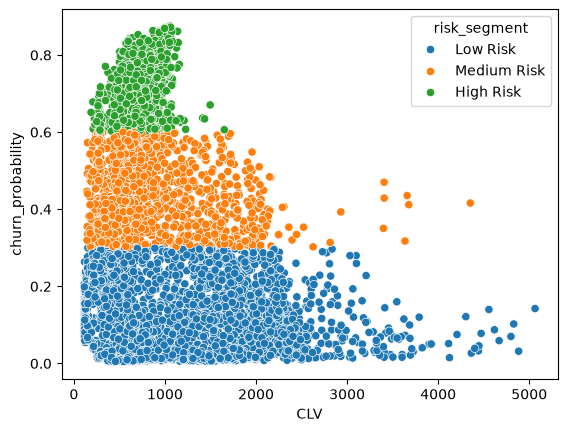

In [27]:
sns.scatterplot(
    x='CLV',
    y='churn_probability',
    hue='risk_segment',
    data=df
)

In [28]:
MODELS_DIR = Path('..') / 'models'
MODELS_DIR.mkdir(exist_ok=True)

CHOSEN_THRESHOLD = 0.30
# Priority ranks the customers the team will contact: active AND flagged at the chosen threshold
targets = df[(df['Churn'] == 0) & (df['churn_probability'] >= CHOSEN_THRESHOLD)]
high_threshold   = targets['priority_score'].quantile(0.75)
medium_threshold = targets['priority_score'].quantile(0.40)
print(f"{len(targets)} target customers | priority thresholds: high {high_threshold:.0f}, medium {medium_threshold:.0f}")

joblib.dump(cal_pipe,         MODELS_DIR / 'churn_pipeline.joblib')   # calibrated model
joblib.dump(contract_medians, MODELS_DIR / 'contract_medians.joblib')
joblib.dump({'high': high_threshold, 'medium': medium_threshold},
            MODELS_DIR / 'priority_thresholds.joblib')

1238 target customers | priority thresholds: high 512, medium 272


['..\\models\\priority_thresholds.joblib']

In [29]:
   import sys; print(sys.executable)

C:\Users\user\.conda\envs\notebook-env\python.exe


## Final Business Recommendations

**Key findings**
- Churn is concentrated in the first year: customers with tenure ≤ 12 months churn at ~48%.
- Month-to-month contracts churn at 42.7% vs 2.8% on two-year contracts.
- Fiber optic customers churn at ~42%. The model shows this effect remains after controlling
  for MonthlyCharges, so it points to service quality or competition more than price alone.
- Electronic check payers churn at 45%, vs 15–17% for automatic payment methods.

**Model decisions**
- Logistic Regression with class_weight='balanced', chosen for interpretability (test ROC-AUC 0.834).
- Sigmoid calibration: mean predicted churn 0.27 = actual rate, Brier 0.174 → 0.141.
  Calibrated probabilities are required because they feed revenue-at-risk and profit figures.
- Threshold 0.30, chosen by expected profit ($50 offer, 30% save rate): near-maximum profit
  with far fewer contacts than lower thresholds.
- Priority score = p^1.5 × CLV × contract weight ranks the flagged customers by expected value at stake.

**Recommended actions**
1. Onboarding programme for the first 12 months, plus an offer to move month-to-month
   customers to a 1-year contract.
2. Investigate fiber optic service quality and competitor pricing.
3. Encourage automatic payment (e.g. a small discount for switching from electronic check).
4. Work the dashboard list top-down by priority score, within the retention team's weekly capacity.